In [5]:
# Libraries import pandrom
import pandas as pd
import matplotlib.pyplot as plt

# Dataset-a read pandrom
df = pd.read_csv(r'C:\Users\mcrcr\Downloads\supply_chain_data.csv')

# First 5 rows paakurathukku
print("Dataset Snapshot:")
print(df.head())

Dataset Snapshot:
  Product type   SKU  Price  Availability  Number of products sold  \
0     haircare  SKU0  69.81            55                      802   
1     skincare  SKU1  14.84            95                      736   
2     haircare  SKU2  11.32            34                        8   
3     skincare  SKU3  61.16            68                       83   
4     skincare  SKU4   4.81            26                      871   

   Revenue generated Customer demographics  Stock levels  Lead times  \
0            8662.00            Non-binary            58           7   
1            7460.90                Female            53          30   
2            9577.75               Unknown             1          10   
3            7766.84            Non-binary            23          13   
4            2686.51            Non-binary             5           3   

   Order quantities  ...  Location Lead time  Production volumes  \
0                96  ...    Mumbai        29                

In [6]:
# Total Revenue (Motha varumanam)
total_revenue = df['Revenue generated'].sum()
print(f"Total Revenue Generated: ${total_revenue:,.2f}")

# Total Manufacturing Cost (Seivatharkana selavu)
total_mfg_cost = df['Manufacturing costs'].sum()
print(f"Total Manufacturing Cost: ${total_mfg_cost:,.2f}")

# Profit calculation (Revenue - Cost)
# Note: Ithu rough profit calculation. Shipping cost-um kuraikkanum actual profit-ku.
rough_profit = total_revenue - total_mfg_cost
print(f"Rough Profit Margin: ${rough_profit:,.2f}")

Total Revenue Generated: $577,604.86
Total Manufacturing Cost: $4,726.64
Rough Profit Margin: $572,878.22



Revenue by Product Type:
Product type
skincare     241628.17
haircare     174455.42
cosmetics    161521.27
Name: Revenue generated, dtype: float64


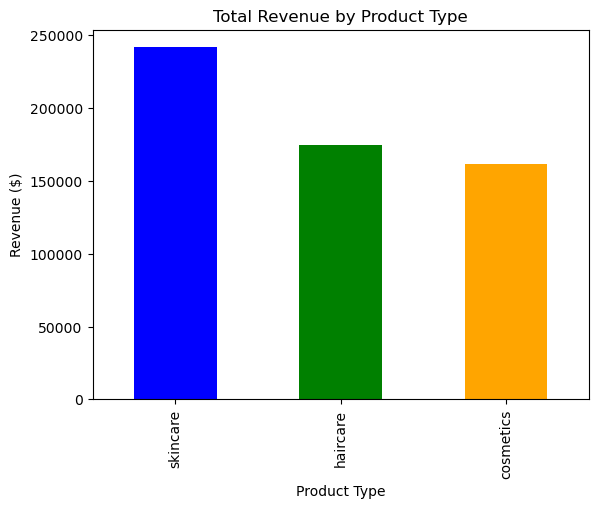

In [7]:
# Product Type vachi Revenue-a group pandrom
revenue_by_product = df.groupby('Product type')['Revenue generated'].sum().sort_values(ascending=False)

print("\nRevenue by Product Type:")
print(revenue_by_product)

# Itha oru Bar Chart-a plot pandrom
revenue_by_product.plot(kind='bar', color=['blue', 'green', 'orange'])
plt.title('Total Revenue by Product Type')
plt.ylabel('Revenue ($)')
plt.xlabel('Product Type')
plt.show()

In [8]:
# Stock level 20-ku keela irukka items-a filter pandrom
low_stock_items = df[df['Stock levels'] < 20]

print(f"\nAlert: {len(low_stock_items)} products are running low on stock!")
# Andha items-oda SKU and Stock level-a mattum print pandrom
print(low_stock_items[['SKU', 'Product type', 'Stock levels']])


Alert: 27 products are running low on stock!
      SKU Product type  Stock levels
2    SKU2     haircare             1
4    SKU4     skincare             5
6    SKU6     skincare            11
8    SKU8    cosmetics             5
9    SKU9     skincare            14
15  SKU15     skincare             9
16  SKU16     skincare             2
18  SKU18     haircare            10
24  SKU24     haircare             4
31  SKU31     skincare             6
33  SKU33    cosmetics             4
34  SKU34     skincare             1
36  SKU36     skincare            18
44  SKU44    cosmetics            13
47  SKU47     skincare             4
57  SKU57     haircare             5
58  SKU58     skincare            10
66  SKU66     skincare            13
67  SKU67     skincare            12
68  SKU68     haircare             0
70  SKU70     haircare            10
73  SKU73    cosmetics            17
75  SKU75     skincare            16
78  SKU78     haircare             5
85  SKU85    cosmetics       

In [9]:
import pandas as pd
import sqlite3

# 1. Dataset-a read pandrom
df = pd.read_csv(r'C:\Users\mcrcr\Downloads\supply_chain_data.csv')

# 2. SQLite Database create pandrom (Memory-la mattum run aagum)
conn = sqlite3.connect(':memory:')

# 3. Namma dataframe-a SQL table-a maathurom (Table name: 'supply_chain')
df.to_sql('supply_chain', conn, index=False)

print("--- SQL QUERY 1: Carrier Performance ---")
# Query 1: Entha Courier (Carrier) adhigama charge pandranga?
query1 = """
SELECT 
    "Shipping carriers", 
    COUNT(SKU) as Total_Shipments,
    AVG("Shipping costs") as Avg_Shipping_Cost 
FROM 
    supply_chain 
GROUP BY 
    "Shipping carriers"
ORDER BY 
    Avg_Shipping_Cost ASC;
"""
result1 = pd.read_sql_query(query1, conn)
print(result1)

print("\n--- SQL QUERY 2: High Risk Suppliers ---")
# Query 2: Entha Supplier adhigama defect (damage) material tharraanga?
query2 = """
SELECT 
    "Supplier name", 
    AVG("Defect rates") as Average_Defect_Rate
FROM 
    supply_chain 
GROUP BY 
    "Supplier name"
ORDER BY 
    Average_Defect_Rate DESC;
"""
result2 = pd.read_sql_query(query2, conn)
print(result2)

# Database connection close pandrom
conn.close()

--- SQL QUERY 1: Carrier Performance ---
  Shipping carriers  Total_Shipments  Avg_Shipping_Cost
0         Carrier B               43           5.509070
1         Carrier A               28           5.555000
2         Carrier C               29           5.599655

--- SQL QUERY 2: High Risk Suppliers ---
  Supplier name  Average_Defect_Rate
0    Supplier 5             2.665408
1    Supplier 3             2.465786
2    Supplier 2             2.362750
3    Supplier 4             2.337397
4    Supplier 1             1.803630
